In [11]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd

from utils.indicators import *
from utils.engine import *

import lightgbm as lgb
from sklearn.metrics import precision_score, recall_score, classification_report
import matplotlib.pyplot as plt

# ============================================================================
# CONFIG
# ============================================================================
LOOKAHEAD_SECONDS   = 240     # how far forward we check if the barrier was hit
BARRIER_MULTIPLIER  = 1.0     # profit/stop barrier = multiplier * horizon-scaled vol
RSI_FILTER_COLUMN   = 'rsi_14'
RSI_FILTER_THRESHOLD = 30
EPS                 = 1e-9    # guards against division by zero

# --- Chronological Validation Settings ---
N_RANDOM_SAMPLES    = 15      # Number of sequential walk-forward folds to test
TEST_BLOCK_SIZE     = 10000   # Number of rows per test chunk
EMBARGO_SECONDS     = LOOKAHEAD_SECONDS

# --- 3-Class Label Encoding ---
# WIN     = profit barrier was reached AND the stop barrier was never breached
# LOSS    = stop barrier was breached (regardless of whether price also
#           technically touched the profit barrier somewhere in the window —
#           this mirrors the original binary logic, which also called that
#           case a "0" since it can't tell barrier-touch order from mfe/mae alone)
# TIMEOUT = neither barrier was breached before the lookahead window ran out
LABEL_LOSS    = 0
LABEL_TIMEOUT = 1
LABEL_WIN     = 2
CLASS_NAMES   = {LABEL_LOSS: 'LOSS', LABEL_TIMEOUT: 'TIMEOUT', LABEL_WIN: 'WIN'}


# ============================================================================
# STEP 1 — Per-session feature pipeline
# ============================================================================
def load_and_build_state_space(orderbook_path, trades_path, session_id):
    df_orderbook = pd.read_csv(orderbook_path)
    df_trades = pd.read_csv(trades_path)

    df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

    df_orderbook = df_orderbook.set_index('datetime').sort_index()
    df_trades = df_trades.set_index('datetime').sort_index()

    df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2

    df_ob_1m = df_orderbook.resample('1min').agg({
        'mid_price': ['first', 'max', 'min', 'last'],
        'bid_price': 'last',
        'ask_price': 'last',
        'bid_amount': 'sum',
        'ask_amount': 'sum',
    })
    df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']
    df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

    df_trades['buy_vol'] = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
    df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

    df_micro = df_trades.resample('1s').agg({
        'price': 'last',
        'buy_vol': 'sum',
        'sell_vol': 'sum'
    }).ffill()

    df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
    df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum()

    df_trades_1m = df_trades.resample('1min').agg({
        'price': ['first', 'max', 'min', 'last', 'count'],
        'amount': 'sum',
        'buy_vol': ['sum', 'max'],
        'sell_vol': ['sum', 'max']
    })
    df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume',
                             'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']
    df_trades_1m = df_trades_1m.dropna(subset=['close'])

    df_price_1m = pd.DataFrame({
        'open': df_ob_1m['open'],
        'high': df_ob_1m['high'],
        'low': df_ob_1m['low'],
        'close': df_ob_1m['close'],
        'largest_buyer': df_trades_1m['largest_buyer'] * 100 / (df_trades_1m['volume'] + EPS),
        'largest_seller': df_trades_1m['largest_seller'] * 100 / (df_trades_1m['volume'] + EPS),
        'OFI_LOB': 100 * (df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount'] + EPS),
        'OFI_AGG': 100 * (df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller'] + EPS),
        'CVD_raw': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
        'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / (abs(df_ob_1m['high'] - df_ob_1m['low']) + EPS),
        'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / ((df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean() + EPS),
    })

    cvd_delta = df_price_1m['CVD_raw'].diff()
    df_price_1m['CVD_z'] = (cvd_delta - cvd_delta.rolling(60).mean()) / (cvd_delta.rolling(60).std() + EPS)
    df_price_1m = df_price_1m.drop(columns=['CVD_raw'])

    price_clean = np.asarray(df_price_1m['close'], dtype=float)
    diffs = np.diff(price_clean)

    def _pad_front(arr, target_len):
        out = np.full(target_len, np.nan)
        out[-len(arr):] = arr
        return out

    df_price_1m['rsi_2'] = _pad_front(get_wilders_rsi(diffs, 2), len(df_price_1m))
    rsi_14_raw = get_wilders_rsi(diffs, 14)
    df_price_1m['rsi_14'] = _pad_front(rsi_14_raw, len(df_price_1m))
    df_price_1m['sma_14'] = _pad_front(sma(rsi_14_raw, 14), len(df_price_1m))

    # FIXED: Lag BOTH 1s micro features AND 1m macro features to eliminate information leakage
    df_micro_shifted = df_micro.shift(1)
    df_macro_shifted = df_price_1m.shift(1)

    df_state_space = df_micro_shifted.join(df_macro_shifted, how='left').ffill()
    df_state_space = df_state_space.dropna()
    df_state_space['session_id'] = session_id

    return df_state_space


# ============================================================================
# STEP 2 — Build combined state space from all sessions
# ============================================================================

session_0 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook.csv", "./csv/BTCUSDT_trades.csv", session_id=0
)
session_1 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_2.csv", "./csv/BTCUSDT_trades_2.csv", session_id=1
)
session_2 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_3.csv", "./csv/BTCUSDT_trades_3.csv", session_id=1
)

df_state_space = pd.concat([session_0, session_1, session_2]).sort_index()

#df_state_space = load_and_build_state_space("./csv/XAUTUSDT_orderbook.csv", "./csv/XAUTUSDT_trades.csv", 0)

# ============================================================================
# STEP 3 — Barrier labeling (Preserving paths for exact backtesting)
# ============================================================================
def add_barrier_labels(df, lookahead_seconds=LOOKAHEAD_SECONDS, barrier_mult=BARRIER_MULTIPLIER):
    labeled = []
    for _, g in df.groupby('session_id', sort=False):
        g = g.copy()
        ret_std_1s = g['price'].pct_change().rolling(window=100).std()
        horizon_std = ret_std_1s * np.sqrt(lookahead_seconds)

        g['profit_barrier'] = horizon_std * barrier_mult
        g['stop_barrier'] = horizon_std * barrier_mult

        forward_max = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .max().iloc[::-1])
        forward_min = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .min().iloc[::-1])

        # Added to capture absolute path deviations & terminal returns accurately
        forward_close = g['price'].shift(-lookahead_seconds)

        g['mfe'] = (forward_max - g['price']) / g['price']
        g['mae'] = (g['price'] - forward_min) / g['price']
        g['terminal_ret'] = (forward_close - g['price']) / g['price']

        valid = g['profit_barrier'].notna() & forward_max.notna() & forward_min.notna()

        # Same underlying comparisons as before, just split into three
        # mutually-exclusive outcomes instead of collapsing "loss" and
        # "timeout" together into a single 0 class.
        is_win = (g['mfe'] >= g['profit_barrier']) & (g['mae'] < g['stop_barrier'])
        is_loss = (g['mae'] >= g['stop_barrier'])
        # anything left over (neither barrier breached inside the window) is a timeout

        g['target'] = np.nan
        g.loc[valid, 'target'] = np.select(
            [is_win[valid], is_loss[valid]],
            [LABEL_WIN, LABEL_LOSS],
            default=LABEL_TIMEOUT
        )
        labeled.append(g)

    out = pd.concat(labeled)
    out = out.dropna(subset=['target'])
    out['target'] = out['target'].astype(int)
    return out

df_state_space = add_barrier_labels(df_state_space)

label_counts = df_state_space['target'].map(CLASS_NAMES).value_counts()
print(f"Label distribution (full dataset): {label_counts.to_dict()}")

df_training_zone = df_state_space[df_state_space[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD]
print(f"Total rows in hunting zone: {len(df_training_zone)}")
print(f"Label distribution (hunting zone): {df_training_zone['target'].map(CLASS_NAMES).value_counts().to_dict()}")


# ============================================================================
# STEP 4 — Features / target configuration
# ============================================================================
# FIXED: Explicitly added backtest telemetry path variables into the training drop list
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close',
             'profit_barrier', 'stop_barrier', 'session_id', 'mfe', 'mae', 'terminal_ret']
features = [c for c in df_training_zone.columns if c not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']


# ============================================================================
# STEP 5 — Purged Chronological Walk-Forward Splitting
# ============================================================================
def purged_chronological_splits(index, n_samples, block_size, horizon_seconds, embargo_seconds=0):
    n = len(index)
    horizon = pd.Timedelta(seconds=horizon_seconds)
    min_initial_train = int(n * 0.35)
    available_test_run = n - min_initial_train - block_size

    if available_test_run <= 0:
        raise ValueError("The dataset length is too narrow for this test configuration block size.")

    step_intervals = available_test_run // n_samples

    for fold in range(n_samples):
        start_idx = min_initial_train + (fold * step_intervals)
        test_idx = np.arange(start_idx, start_idx + block_size)
        test_start_time = index[test_idx[0]]

        possible_train_idx = np.arange(0, start_idx)
        train_times = index[possible_train_idx]

        purge_mask = (train_times + horizon >= test_start_time)
        train_idx = possible_train_idx[~purge_mask]

        n_purged = len(possible_train_idx) - len(train_idx)
        yield train_idx, test_idx, n_purged

splitter = purged_chronological_splits(
    X.index,
    n_samples=N_RANDOM_SAMPLES,
    block_size=TEST_BLOCK_SIZE,
    horizon_seconds=LOOKAHEAD_SECONDS,
    embargo_seconds=EMBARGO_SECONDS
)

print(f"\n--- Starting {N_RANDOM_SAMPLES} Chronological Walk-Forward Validation Folds (Size: {TEST_BLOCK_SIZE}) ---")

thresholds_to_track = np.arange(0.50, 0.96, 0.05)
fold_metrics = {t: {'precisions': [], 'trades': []} for t in thresholds_to_track}
fold_importances = []

for fold, (train_idx, test_idx, n_purged) in enumerate(splitter, start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    if len(X_train) == 0 or y_train.nunique() < 2:
        print(f"Fold {fold} | skipped — invalid training data distribution.")
        continue

    # scale_pos_weight is a binary-only LightGBM knob, so imbalance across the
    # three classes (LOSS / TIMEOUT / WIN) is handled with class_weight='balanced'
    # instead — the multiclass equivalent of the original neg_pos_ratio reweighting.
    clf = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    clf.fit(X_train, y_train)

    if LABEL_WIN not in clf.classes_:
        print(f"Fold {fold} | skipped scoring — no WIN samples present in this fold's training data.")
        continue

    # predict_proba now returns one column per class present in this fold;
    # we pull out the WIN column, which is the direct multiclass analogue of
    # the old binary predict_proba(...)[:, 1] "probability of a winning trade".
    win_idx = list(clf.classes_).index(LABEL_WIN)
    y_proba = clf.predict_proba(X_test)[:, win_idx]
    y_test_is_win = (y_test == LABEL_WIN).astype(int)

    for t in thresholds_to_track:
        preds = (y_proba >= t).astype(int)
        prec = precision_score(y_test_is_win, preds, zero_division=0)
        num_trades = int(preds.sum())

        if num_trades > 0:
            fold_metrics[t]['precisions'].append(prec)
        fold_metrics[t]['trades'].append(num_trades)

    fold_importances.append(clf.feature_importances_)
    print(f"Fold {fold:02d} | Train Rows: {len(X_train):<6} | Tested on forward {TEST_BLOCK_SIZE} rows. Purged: {n_purged}")


# ============================================================================
# STEP 6 — Threshold Fluctuation Reporting
# ============================================================================
print("\n--- Edge Stability Across Chronological Windows (Honest Analysis, WIN class) ---")
print("-" * 75)
print(f"{'Threshold':<10} | {'Mean Prec':<11} | {'Std Dev (Fluct)':<16} | {'Avg Trades per Block'}")
print("-" * 75)

for t in thresholds_to_track:
    prec_array = np.array(fold_metrics[t]['precisions'])
    trades_array = np.array(fold_metrics[t]['trades'])

    if len(prec_array) > 0:
        mean_prec = np.mean(prec_array)
        std_prec = np.std(prec_array)
        mean_trades = np.mean(trades_array)

        print(f">= {t*100:>4.1f}%   | {mean_prec:>9.2%}   | ± {std_prec:<13.2%} | {mean_trades:>6.1f}")
    else:
        print(f">= {t*100:>4.1f}%   | No trades fired in any test block.")

print("-" * 75)

if fold_importances:
    imp_df = pd.DataFrame(fold_importances, columns=features)
    imp_summary = pd.DataFrame({
        'mean_importance': imp_df.mean(),
        'std_importance': imp_df.std()
    }).sort_values('mean_importance', ascending=False)

    print("\n--- Top 10 Feature Importance Stability ---")
    print(imp_summary.head(10))

Label distribution (full dataset): {'TIMEOUT': 440713, 'LOSS': 327235, 'WIN': 122991}
Total rows in hunting zone: 239940
Label distribution (hunting zone): {'TIMEOUT': 126186, 'LOSS': 108570, 'WIN': 5184}

--- Starting 15 Chronological Walk-Forward Validation Folds (Size: 10000) ---
Fold 01 | Train Rows: 83739  | Tested on forward 10000 rows. Purged: 240
Fold 02 | Train Rows: 93469  | Tested on forward 10000 rows. Purged: 240
Fold 03 | Train Rows: 103199 | Tested on forward 10000 rows. Purged: 240
Fold 04 | Train Rows: 112929 | Tested on forward 10000 rows. Purged: 240
Fold 05 | Train Rows: 122659 | Tested on forward 10000 rows. Purged: 240
Fold 06 | Train Rows: 132389 | Tested on forward 10000 rows. Purged: 240
Fold 07 | Train Rows: 142119 | Tested on forward 10000 rows. Purged: 240
Fold 08 | Train Rows: 151849 | Tested on forward 10000 rows. Purged: 240
Fold 09 | Train Rows: 161640 | Tested on forward 10000 rows. Purged: 179
Fold 10 | Train Rows: 171309 | Tested on forward 10000 rows

# Patch for ml-state code by AI
Integrate random splitting of data to ensure the code truly works and there is no overfitting problem. How we test the stability of machine learning algo:
- Run on large-sample sized splits (20k). Measure Mean Precision of trades across sample size then get Std Dev to get flucutation of performance in machine learning algo.
- Deduce based on expectancy formula if strtaegy is profitable or not. Further validation by changing sample size, switching tickers, etc.

# Conclusion (20k samples)
![performance](./image/img_12.png)

With condition 2RR, trading on 85%-95% shows a very stable edge.
- Average no of trades: 5.67 trades per hour
- 85.0%: 52.36% * 2RR - 47.64% = 0.5708RR
- Worst condition: (52.36% - 22.98%) * 2RR - (100% - 52.36% + 22.98%) = 0.5876 - 0.7062 = -0.1186RR
- Using assumption that it is a normal distribution, 65% of the time, the model performs reasonably well and generally has a positive expectancy. However there is a 5% chance that the model experiences severe underperformance (2x stdev)

# Conclusion (10k samples split)
![Performance](./image/img_13.png)

With condition 2RR, trading on 85%-95% shows a very stable edge.
- Average no of trades: 3.348 trades per hour
- 85.0%: 62.37% * 2RR - 37.63% = 0.8711RR
- Worst condition: (62.37% - 21.44%) * 2RR - (100% - 62.37% + 21.44%) = 0.8186 - 0.5907 = 0.2279RR
- Using assumption that it is a normal distribution, 65% of the time, the model performs exceptionally well and generally has a positive expectancy even when the market is 1stdev worse. For the strategy to hit breakeven, it should hit the 1.38x stdev area.

Nevermind ignore this conclusion for now. realized lookahead bias

Label distribution (full dataset): {'LOSS': 84857, 'TIMEOUT': 27526, 'WIN': 26097}
Total rows in hunting zone: 42720
Label distribution (hunting zone): {'LOSS': 40295, 'WIN': 1292, 'TIMEOUT': 1133}

--- Starting 15 Chronological Walk-Forward Validation Folds (Size: 10000) ---
Fold 01 | Train Rows: 14711  | Tested on forward 10000 rows. Purged: 240
Fold 02 | Train Rows: 15895  | Tested on forward 10000 rows. Purged: 240
Fold 03 | Train Rows: 17079  | Tested on forward 10000 rows. Purged: 240
Fold 04 | Train Rows: 18263  | Tested on forward 10000 rows. Purged: 240
Fold 05 | Train Rows: 19447  | Tested on forward 10000 rows. Purged: 240
Fold 06 | Train Rows: 20631  | Tested on forward 10000 rows. Purged: 240
Fold 07 | Train Rows: 21815  | Tested on forward 10000 rows. Purged: 240
Fold 08 | Train Rows: 22999  | Tested on forward 10000 rows. Purged: 240
Fold 09 | Train Rows: 24183  | Tested on forward 10000 rows. Purged: 240
Fold 10 | Train Rows: 25367  | Tested on forward 10000 rows. Purge

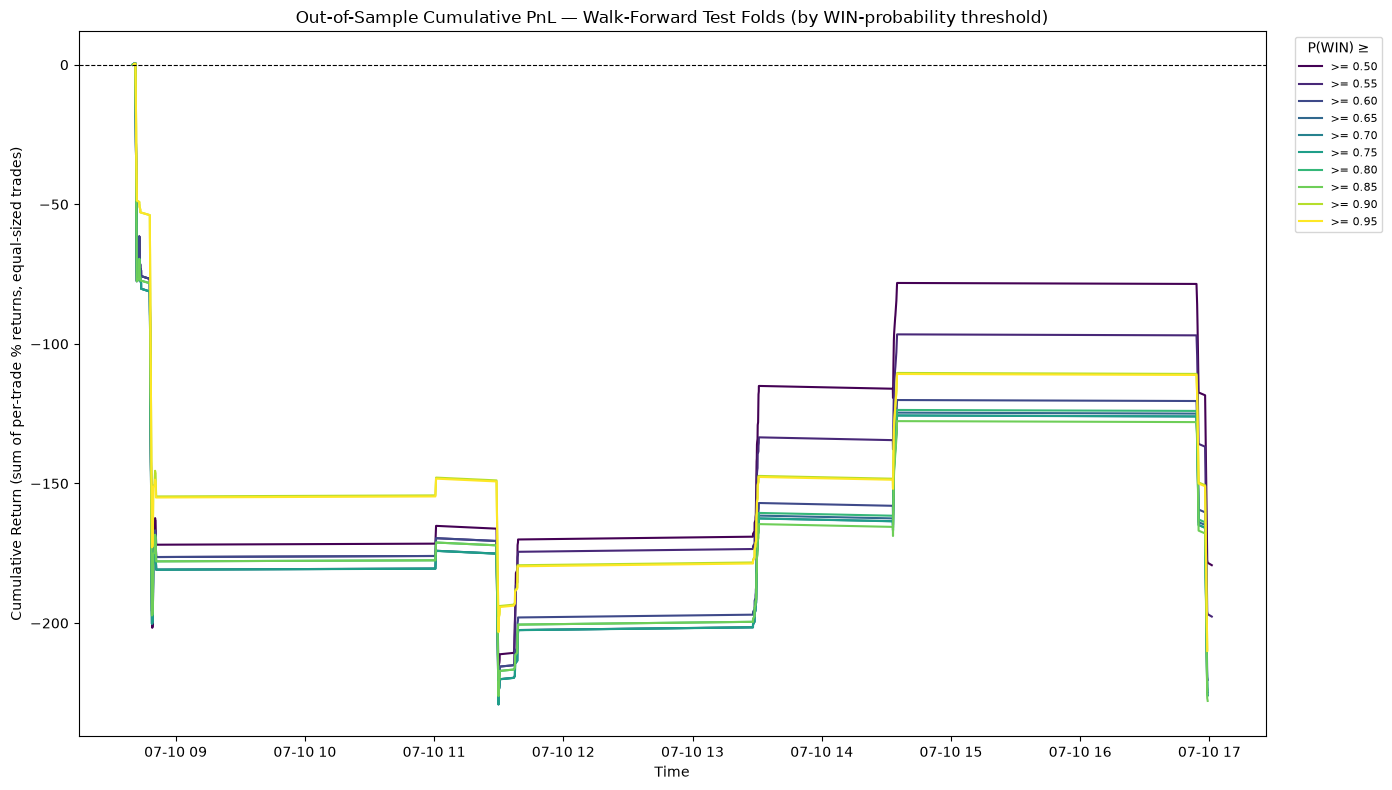


Saved chart to pnl_walkforward.png


In [22]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

import numpy as np
import pandas as pd

from utils.indicators import *
from utils.engine import *

import lightgbm as lgb
from sklearn.metrics import precision_score, recall_score, classification_report
import matplotlib.pyplot as plt

# ============================================================================
# CONFIG
# ============================================================================
LOOKAHEAD_SECONDS   = 240     # how far forward we check if the barrier was hit
BARRIER_MULTIPLIER  = 1.0     # profit/stop barrier = multiplier * horizon-scaled vol
RSI_FILTER_COLUMN   = 'rsi_14'
RSI_FILTER_THRESHOLD = 30
EPS                 = 1e-9    # guards against division by zero

# --- Chronological Validation Settings ---
N_RANDOM_SAMPLES    = 15      # Number of sequential walk-forward folds to test
TEST_BLOCK_SIZE     = 10000   # Number of rows per test chunk
EMBARGO_SECONDS     = LOOKAHEAD_SECONDS

# --- 3-Class Label Encoding ---
# WIN     = profit barrier was reached AND the stop barrier was never breached
# LOSS    = stop barrier was breached (regardless of whether price also
#           technically touched the profit barrier somewhere in the window —
#           this mirrors the original binary logic, which also called that
#           case a "0" since it can't tell barrier-touch order from mfe/mae alone)
# TIMEOUT = neither barrier was breached before the lookahead window ran out
LABEL_LOSS    = 0
LABEL_TIMEOUT = 1
LABEL_WIN     = 2
CLASS_NAMES   = {LABEL_LOSS: 'LOSS', LABEL_TIMEOUT: 'TIMEOUT', LABEL_WIN: 'WIN'}


# ============================================================================
# STEP 1 — Per-session feature pipeline
# ============================================================================
def load_and_build_state_space(orderbook_path, trades_path, session_id):
    df_orderbook = pd.read_csv(orderbook_path)
    df_trades = pd.read_csv(trades_path)

    df_orderbook['datetime'] = pd.to_datetime(df_orderbook['timestamp'], unit='ms')
    df_trades['datetime'] = pd.to_datetime(df_trades['timestamp'], unit='ms')

    df_orderbook = df_orderbook.set_index('datetime').sort_index()
    df_trades = df_trades.set_index('datetime').sort_index()

    df_orderbook['mid_price'] = (df_orderbook['bid_price'] + df_orderbook['ask_price']) / 2

    df_ob_1m = df_orderbook.resample('1min').agg({
        'mid_price': ['first', 'max', 'min', 'last'],
        'bid_price': 'last',
        'ask_price': 'last',
        'bid_amount': 'sum',
        'ask_amount': 'sum',
    })
    df_ob_1m.columns = ['open', 'high', 'low', 'close', 'bid_price', 'ask_price', 'bid_amount', 'ask_amount']
    df_ob_1m['spread'] = df_ob_1m['ask_price'] - df_ob_1m['bid_price']

    df_trades['buy_vol'] = df_trades['amount'].where(df_trades['side'] == 'buy', 0)
    df_trades['sell_vol'] = df_trades['amount'].where(df_trades['side'] == 'sell', 0)

    df_micro = df_trades.resample('1s').agg({
        'price': 'last',
        'buy_vol': 'sum',
        'sell_vol': 'sum'
    }).ffill()

    df_micro['micro_OFI'] = df_micro['buy_vol'] - df_micro['sell_vol']
    df_micro['micro_CVD'] = df_micro['micro_OFI'].rolling(10).sum()

    df_trades_1m = df_trades.resample('1min').agg({
        'price': ['first', 'max', 'min', 'last', 'count'],
        'amount': 'sum',
        'buy_vol': ['sum', 'max'],
        'sell_vol': ['sum', 'max']
    })
    df_trades_1m.columns = ['open', 'high', 'low', 'close', 'num_trades', 'volume',
                             'agg_buyer', 'largest_buyer', 'agg_seller', 'largest_seller']
    df_trades_1m = df_trades_1m.dropna(subset=['close'])

    df_price_1m = pd.DataFrame({
        'open': df_ob_1m['open'],
        'high': df_ob_1m['high'],
        'low': df_ob_1m['low'],
        'close': df_ob_1m['close'],
        'largest_buyer': df_trades_1m['largest_buyer'] * 100 / (df_trades_1m['volume'] + EPS),
        'largest_seller': df_trades_1m['largest_seller'] * 100 / (df_trades_1m['volume'] + EPS),
        'OFI_LOB': 100 * (df_ob_1m['bid_amount'] - df_ob_1m['ask_amount']) / (df_ob_1m['bid_amount'] + df_ob_1m['ask_amount'] + EPS),
        'OFI_AGG': 100 * (df_trades_1m['agg_buyer'] - df_trades_1m['agg_seller']) / (df_trades_1m['agg_buyer'] + df_trades_1m['agg_seller'] + EPS),
        'CVD_raw': calculate_cvd(df_trades_1m['agg_buyer'], df_trades_1m['agg_seller']),
        'candle_type': abs(df_ob_1m['close'] - df_ob_1m['open']) / (abs(df_ob_1m['high'] - df_ob_1m['low']) + EPS),
        'candle_size': (df_ob_1m['high'] - df_ob_1m['low']) / ((df_ob_1m['high'] - df_ob_1m['low']).rolling(14).mean() + EPS),
    })

    cvd_delta = df_price_1m['CVD_raw'].diff()
    df_price_1m['CVD_z'] = (cvd_delta - cvd_delta.rolling(60).mean()) / (cvd_delta.rolling(60).std() + EPS)
    df_price_1m = df_price_1m.drop(columns=['CVD_raw'])

    price_clean = np.asarray(df_price_1m['close'], dtype=float)
    diffs = np.diff(price_clean)

    def _pad_front(arr, target_len):
        out = np.full(target_len, np.nan)
        out[-len(arr):] = arr
        return out

    df_price_1m['rsi_2'] = _pad_front(get_wilders_rsi(diffs, 2), len(df_price_1m))
    rsi_14_raw = get_wilders_rsi(diffs, 14)
    df_price_1m['rsi_14'] = _pad_front(rsi_14_raw, len(df_price_1m))
    df_price_1m['sma_14'] = _pad_front(sma(rsi_14_raw, 14), len(df_price_1m))

    # FIXED: Lag BOTH 1s micro features AND 1m macro features to eliminate information leakage
    df_micro_shifted = df_micro.shift(1)
    df_macro_shifted = df_price_1m.shift(1)

    df_state_space = df_micro_shifted.join(df_macro_shifted, how='left').ffill()
    df_state_space = df_state_space.dropna()
    df_state_space['session_id'] = session_id

    return df_state_space


# ============================================================================
# STEP 2 — Build combined state space from all sessions
# ============================================================================

"""
session_0 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook.csv", "./csv/BTCUSDT_trades.csv", session_id=0
)
session_1 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_2.csv", "./csv/BTCUSDT_trades_2.csv", session_id=1
)
session_2 = load_and_build_state_space(
    "./csv/BTCUSDT_orderbook_3.csv", "./csv/BTCUSDT_trades_3.csv", session_id=1
)

df_state_space = pd.concat([session_0, session_1, session_2]).sort_index()
"""

df_state_space = load_and_build_state_space("./csv/XAUTUSDT_orderbook.csv", "./csv/XAUTUSDT_trades.csv", 0)

# ============================================================================
# STEP 3 — Barrier labeling (Preserving paths for exact backtesting)
# ============================================================================
def add_barrier_labels(df, lookahead_seconds=LOOKAHEAD_SECONDS, barrier_mult=BARRIER_MULTIPLIER):
    labeled = []
    for _, g in df.groupby('session_id', sort=False):
        g = g.copy()
        ret_std_1s = g['price'].pct_change().rolling(window=100).std()
        horizon_std = ret_std_1s * np.sqrt(lookahead_seconds)

        g['profit_barrier'] = horizon_std * barrier_mult
        g['stop_barrier'] = horizon_std * barrier_mult

        forward_max = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .max().iloc[::-1])
        forward_min = (g['price'].iloc[::-1]
                       .rolling(window=lookahead_seconds, min_periods=lookahead_seconds)
                       .min().iloc[::-1])

        # Added to capture absolute path deviations & terminal returns accurately
        forward_close = g['price'].shift(-lookahead_seconds)

        g['mfe'] = (forward_max - g['price']) / g['price']
        g['mae'] = (g['price'] - forward_min) / g['price']
        g['terminal_ret'] = (forward_close - g['price']) / g['price']

        valid = g['profit_barrier'].notna() & forward_max.notna() & forward_min.notna()

        # Same underlying comparisons as before, just split into three
        # mutually-exclusive outcomes instead of collapsing "loss" and
        # "timeout" together into a single 0 class.
        is_win = (g['mfe'] >= g['profit_barrier']) & (g['mae'] < g['stop_barrier'])
        is_loss = (g['mae'] >= g['stop_barrier'])
        # anything left over (neither barrier breached inside the window) is a timeout

        g['target'] = np.nan
        g.loc[valid, 'target'] = np.select(
            [is_win[valid], is_loss[valid]],
            [LABEL_WIN, LABEL_LOSS],
            default=LABEL_TIMEOUT
        )
        labeled.append(g)

    out = pd.concat(labeled)
    out = out.dropna(subset=['target'])
    out['target'] = out['target'].astype(int)
    return out

df_state_space = add_barrier_labels(df_state_space)

label_counts = df_state_space['target'].map(CLASS_NAMES).value_counts()
print(f"Label distribution (full dataset): {label_counts.to_dict()}")

df_training_zone = df_state_space[df_state_space[RSI_FILTER_COLUMN] < RSI_FILTER_THRESHOLD]
print(f"Total rows in hunting zone: {len(df_training_zone)}")
print(f"Label distribution (hunting zone): {df_training_zone['target'].map(CLASS_NAMES).value_counts().to_dict()}")


# ============================================================================
# STEP 4 — Features / target configuration
# ============================================================================
# FIXED: Explicitly added backtest telemetry path variables into the training drop list
drop_cols = ['target', 'price', 'open', 'high', 'low', 'close',
             'profit_barrier', 'stop_barrier', 'session_id', 'mfe', 'mae', 'terminal_ret']
features = [c for c in df_training_zone.columns if c not in drop_cols]

X = df_training_zone[features]
y = df_training_zone['target']

# ============================================================================
# STEP 4.5 — Risk-Normalized Return (R-Multiple Bookkeeping)
# ----------------------------------------------------------------------------
# We normalize the return of every trade by dividing it by the stop_barrier.
# This simulates perfect position sizing where every trade risks exactly 1 unit (1R).
# ============================================================================
normalized_return = pd.Series(index=df_training_zone.index, dtype=float)
win_mask = df_training_zone['target'] == LABEL_WIN
loss_mask = df_training_zone['target'] == LABEL_LOSS
timeout_mask = df_training_zone['target'] == LABEL_TIMEOUT

# Wins are +1R, Losses are -1R
normalized_return[win_mask] = 1.0
normalized_return[loss_mask] = -1.0

# Timeouts are a fraction of the stop barrier: e.g., if terminal_ret is +0.2% 
# and stop_barrier was 0.5%, the normalized return is +0.4R
normalized_return[timeout_mask] = (
    df_training_zone.loc[timeout_mask, 'terminal_ret'] / 
    (df_training_zone.loc[timeout_mask, 'stop_barrier'] + EPS)
)

# ============================================================================
# STEP 5 — Purged Chronological Walk-Forward Splitting
# ============================================================================
def purged_chronological_splits(index, n_samples, block_size, horizon_seconds, embargo_seconds=0):
    n = len(index)
    horizon = pd.Timedelta(seconds=horizon_seconds)
    min_initial_train = int(n * 0.35)
    available_test_run = n - min_initial_train - block_size

    if available_test_run <= 0:
        raise ValueError("The dataset length is too narrow for this test configuration block size.")

    step_intervals = available_test_run // n_samples

    for fold in range(n_samples):
        start_idx = min_initial_train + (fold * step_intervals)
        test_idx = np.arange(start_idx, start_idx + block_size)
        test_start_time = index[test_idx[0]]

        possible_train_idx = np.arange(0, start_idx)
        train_times = index[possible_train_idx]

        purge_mask = (train_times + horizon >= test_start_time)
        train_idx = possible_train_idx[~purge_mask]

        n_purged = len(possible_train_idx) - len(train_idx)
        yield train_idx, test_idx, n_purged

splitter = purged_chronological_splits(
    X.index,
    n_samples=N_RANDOM_SAMPLES,
    block_size=TEST_BLOCK_SIZE,
    horizon_seconds=LOOKAHEAD_SECONDS,
    embargo_seconds=EMBARGO_SECONDS
)

print(f"\n--- Starting {N_RANDOM_SAMPLES} Chronological Walk-Forward Validation Folds (Size: {TEST_BLOCK_SIZE}) ---")

thresholds_to_track = np.arange(0.50, 0.96, 0.05)
fold_metrics = {t: {'precisions': [], 'win_rates': [], 'rrs': [], 'trades': []} for t in thresholds_to_track}
fold_importances = []
trade_log = {t: [] for t in thresholds_to_track}       # (timestamp, realized_return) per taken trade
fold_detail_records = []                                # one row per fold x threshold that fired >=1 trade

for fold, (train_idx, test_idx, n_purged) in enumerate(splitter, start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    if len(X_train) == 0 or y_train.nunique() < 2:
        print(f"Fold {fold} | skipped — invalid training data distribution.")
        continue

    # scale_pos_weight is a binary-only LightGBM knob, so imbalance across the
    # three classes (LOSS / TIMEOUT / WIN) is handled with class_weight='balanced'
    # instead — the multiclass equivalent of the original neg_pos_ratio reweighting.
    clf = lgb.LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        num_leaves=31,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    clf.fit(X_train, y_train)

    if LABEL_WIN not in clf.classes_:
        print(f"Fold {fold} | skipped scoring — no WIN samples present in this fold's training data.")
        continue

    # predict_proba now returns one column per class present in this fold;
    # we pull out the WIN column, which is the direct multiclass analogue of
    # the old binary predict_proba(...)[:, 1] "probability of a winning trade".
    win_idx = list(clf.classes_).index(LABEL_WIN)
    y_proba = clf.predict_proba(X_test)[:, win_idx]
    y_test_is_win = (y_test == LABEL_WIN).astype(int)

    for t in thresholds_to_track:
        preds = (y_proba >= t).astype(int)
        prec = precision_score(y_test_is_win, preds, zero_division=0)
        num_trades = int(preds.sum())

        if num_trades > 0:
            fold_metrics[t]['precisions'].append(prec)

            traded_idx = X_test.index[preds == 1]
            traded_targets = y_test.loc[traded_idx]
            
            # FIXED: Changed from realized_return to normalized_return
            traded_returns = normalized_return.loc[traded_idx] 

            trade_log[t].extend(zip(traded_idx, traded_returns.values))

            num_win = int((traded_targets == LABEL_WIN).sum())
            num_loss = int((traded_targets == LABEL_LOSS).sum())
            num_timeout = int((traded_targets == LABEL_TIMEOUT).sum())

            win_rate = num_win / (num_win + num_loss) if (num_win + num_loss) > 0 else np.nan

            # FIXED: Calculate Risk-Reward using the clean 1R / -1R units
            avg_win_ret = traded_returns[traded_targets == LABEL_WIN].mean() if num_win > 0 else np.nan
            avg_loss_ret = traded_returns[traded_targets == LABEL_LOSS].mean() if num_loss > 0 else np.nan
            rr = (avg_win_ret / abs(avg_loss_ret)) if (num_win > 0 and num_loss > 0 and avg_loss_ret != 0) else np.nan

            fold_metrics[t]['win_rates'].append(win_rate)
            fold_metrics[t]['rrs'].append(rr)

            fold_detail_records.append({
                'threshold': round(float(t), 2),
                'fold': fold,
                'trades': num_trades,
                'wins': num_win,
                'losses': num_loss,
                'timeouts': num_timeout,
                'precision': prec,
                'win_rate': win_rate,
                'rr': rr,
                'avg_return': traded_returns.mean(),
            })

        fold_metrics[t]['trades'].append(num_trades)

    fold_importances.append(clf.feature_importances_)
    print(f"Fold {fold:02d} | Train Rows: {len(X_train):<6} | Tested on forward {TEST_BLOCK_SIZE} rows. Purged: {n_purged}")


# ============================================================================
# STEP 6 — Full Trade Performance Analysis (Precision, Win Rate, RR)
# ----------------------------------------------------------------------------
# Precision = WIN / (WIN + LOSS + TIMEOUT) among taken trades — how many of
#             ALL fired trades ended up a full win (same metric as before).
# Win Rate  = WIN / (WIN + LOSS) among taken trades — excludes timeouts, so
#             it isolates the win rate of trades that actually resolved at a
#             barrier, uncontaminated by how often signals simply expire.
# RR        = mean(realized WIN return) / mean(|realized LOSS return|).
# ============================================================================
print("\n--- Aggregate Performance by Threshold (Mean ± Std Across Folds) ---")
print("-" * 100)
print(f"{'Threshold':<10} | {'Precision':<18} | {'Win Rate':<18} | {'RR':<14} | {'Avg Trades/Blk'}")
print("-" * 100)

for t in thresholds_to_track:
    prec_array = np.array(fold_metrics[t]['precisions'])
    wr_array = np.array([w for w in fold_metrics[t]['win_rates'] if not np.isnan(w)])
    rr_array = np.array([r for r in fold_metrics[t]['rrs'] if not np.isnan(r)])
    trades_array = np.array(fold_metrics[t]['trades'])

    if len(prec_array) > 0:
        mean_prec, std_prec = np.mean(prec_array), np.std(prec_array)
        mean_trades = np.mean(trades_array)

        prec_txt = f"{mean_prec:>6.2%} \u00b1 {std_prec:<6.2%}"
        wr_txt = f"{np.mean(wr_array):>6.2%} \u00b1 {np.std(wr_array):<6.2%}" if len(wr_array) > 0 else "n/a"
        rr_txt = f"{np.mean(rr_array):>5.2f} \u00b1 {np.std(rr_array):<5.2f}" if len(rr_array) > 0 else "n/a"

        print(f">= {t*100:>4.1f}%   | {prec_txt:<18} | {wr_txt:<18} | {rr_txt:<14} | {mean_trades:>6.1f}")
    else:
        print(f">= {t*100:>4.1f}%   | No trades fired in any test block.")

print("-" * 100)
# ============================================================================
# STEP 6 — FIX: Print table in R-multiples instead of percentages
# ============================================================================
print("\n--- Per-Fold Detail (every fold x threshold that fired at least one trade) ---")
fold_detail_df = pd.DataFrame(fold_detail_records)

if not fold_detail_df.empty:
    fold_detail_df = fold_detail_df.sort_values(['threshold', 'fold']).reset_index(drop=True)

    display_df = fold_detail_df.copy()
    display_df['precision'] = display_df['precision'].map('{:.2%}'.format)
    display_df['win_rate'] = display_df['win_rate'].map(lambda v: f'{v:.2%}' if pd.notna(v) else 'n/a')
    display_df['rr'] = display_df['rr'].map(lambda v: f'{v:.2f}' if pd.notna(v) else 'n/a')
    
    # FIXED: Map to standard decimal float with an 'R' suffix instead of multiplying by 100
    display_df['avg_return'] = display_df['avg_return'].map('{:.3f}R'.format)

    print(display_df.to_string(index=False))
    
    fold_detail_df.to_csv('fold_performance_detail.csv', index=False)
    print("\nSaved full per-fold detail (raw, unformatted numbers) to fold_performance_detail.csv")
else:
    print("No trades fired in any fold/threshold combination.")

if fold_importances:
    imp_df = pd.DataFrame(fold_importances, columns=features)
    imp_summary = pd.DataFrame({
        'mean_importance': imp_df.mean(),
        'std_importance': imp_df.std()
    }).sort_values('mean_importance', ascending=False)

    print("\n--- Top 10 Feature Importance Stability ---")
    print(imp_summary.head(10))


# ============================================================================
# STEP 7 — Out-of-Sample PnL Chart (Walk-Forward)
# ----------------------------------------------------------------------------
# Same folds, same thresholds, same trades as Steps 5-6 above — this just
# takes the trades each threshold already fired (trade_log) and lays them out
# chronologically as a cumulative-return curve. Note: if TEST_BLOCK_SIZE is
# larger than the step between fold start points, test windows overlap across
# folds, meaning some timestamps get traded by more than one fold's model —
# that's inherent to the walk-forward setup above, not something changed here.
# ============================================================================
print("\n--- Out-of-Sample PnL Summary (Walk-Forward) ---")
print("-" * 60)
print(f"{'Threshold':<10} | {'# Trades':<10} | {'Final Cum. Return'}")
print("-" * 60)

plt.figure(figsize=(14, 8))
cmap = plt.get_cmap('viridis')

for i, t in enumerate(thresholds_to_track):
    if len(trade_log[t]) == 0:
        print(f">= {t*100:>4.1f}%   | {0:<10} | n/a")
        continue

    log_df = pd.DataFrame(trade_log[t], columns=['datetime', 'ret']).sort_values('datetime')
    log_df['cum_pnl'] = log_df['ret'].cumsum()

    print(f">= {t*100:>4.1f}%   | {len(log_df):<10} | {log_df['cum_pnl'].iloc[-1]:.2%}")

    color = cmap(i / max(len(thresholds_to_track) - 1, 1))
    plt.plot(log_df['datetime'], log_df['cum_pnl'], label=f'>= {t:.2f}', color=color)

print("-" * 60)

plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Out-of-Sample Cumulative PnL — Walk-Forward Test Folds (by WIN-probability threshold)')
plt.xlabel('Time')
plt.ylabel('Cumulative Return (sum of per-trade % returns, equal-sized trades)')
plt.legend(title='P(WIN) ≥', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig('pnl_walkforward.png', dpi=150)
plt.show()
print("\nSaved chart to pnl_walkforward.png")

# Linear Split 80/20
Before its following chronological split system.

Training on 191880 rows (Purged), Testing on 47988 rows...

 📈 STRATEGY PERFORMANCE SUMMARY (SHORT OUT OF SAMPLE)
Total Trades Taken : 112
Win Rate           : 68.75%
Total Net Return   : 11.27% (Fixed size)
Max Drawdown       : -0.64%
Daily Sharpe Ratio : 10.18


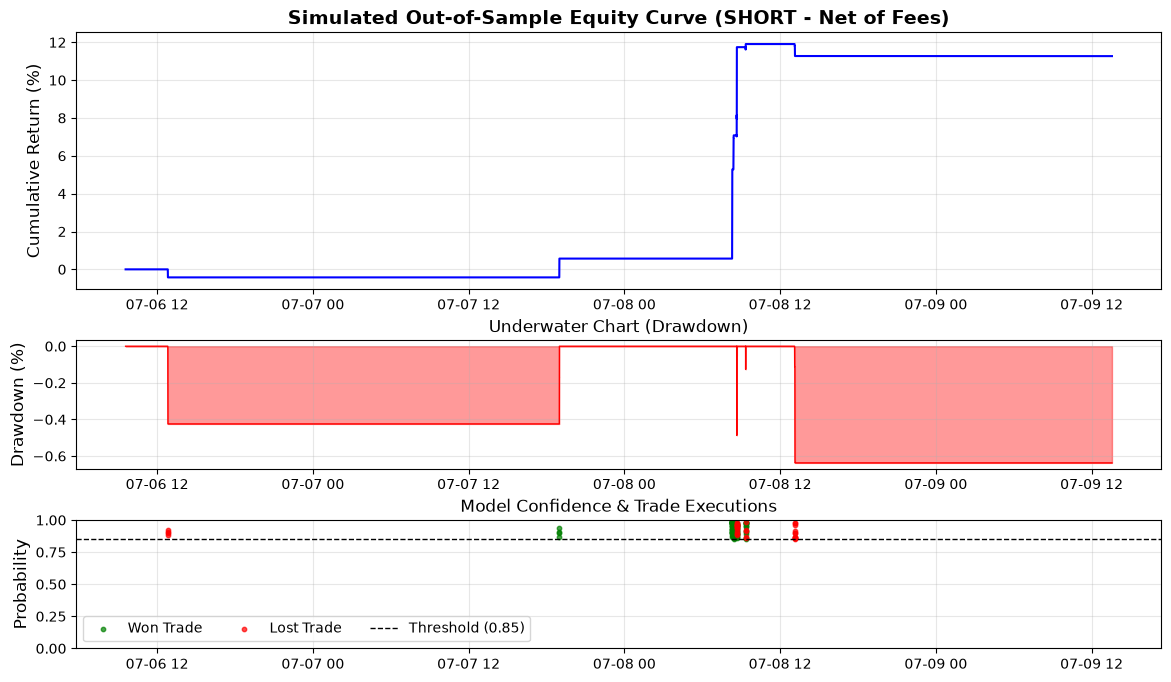


 🛡️ RISK METRICS
Avg Stop Barrier (Designed Risk) : 0.21%
Avg Actual Loss (on losers)      : 0.05%
Risk-Reward Ratio (Avg)          : 3.25
Profit Hits: 9
Stop Hits:   22
Time Outs:   81


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from matplotlib.gridspec import GridSpec

# ============================================================================
# CONFIG FOR BACKTEST
# ============================================================================
CONFIDENCE_THRESHOLD = 0.85  # Model probability required to fire a trade
STRATEGY_TYPE        = 'SHORT' # Options: 'LONG' or 'SHORT' (Fade the long model safely)
FEE_BPS              = 0.0     # Assumed execution fee in basis points (e.g., Binance taker)
TRAIN_TEST_SPLIT     = 0.80    # 80% train, 20% chronological test

fee_pct = FEE_BPS / 10000

# ============================================================================
# STEP 1 — Chronological Split with Boundary Purging
# ============================================================================
df_bt = df_training_zone.sort_index().copy()

split_idx = int(len(df_bt) * TRAIN_TEST_SPLIT)
test_data = df_bt.iloc[split_idx:].copy()

# FIXED: Purge the end of the training data block to eliminate edge leakage into test data
horizon = pd.Timedelta(seconds=LOOKAHEAD_SECONDS)
train_data_raw = df_bt.iloc[:split_idx]
train_data = train_data_raw[train_data_raw.index + horizon < test_data.index[0]]

X_train_bt = train_data[features]
y_train_bt = train_data['target']
X_test_bt = test_data[features]
y_test_bt = test_data['target']

# ============================================================================
# STEP 2 — Train Model
# ============================================================================
neg_pos_ratio = sum(y_train_bt == 0) / max(sum(y_train_bt == 1), 1)

clf_bt = lgb.LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    num_leaves=31,
    scale_pos_weight=neg_pos_ratio,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

print(f"Training on {len(X_train_bt)} rows (Purged), Testing on {len(X_test_bt)} rows...")
clf_bt.fit(X_train_bt, y_train_bt)

# ============================================================================
# STEP 3 — Generate Signals & Path-Dependent Vectorized PnL Calculation
# ============================================================================
# 1. Generate the probability and signal first
test_data['prob'] = clf_bt.predict_proba(X_test_bt)[:, 1]
test_data['signal'] = (test_data['prob'] >= CONFIDENCE_THRESHOLD).astype(int)

# 2. Define the mask AFTER signal is created
traded_mask = test_data['signal'] == 1

# 3. Define exact barrier paths
hit_upside    = (test_data['mfe'] >= test_data['profit_barrier']) & (test_data['mae'] < test_data['stop_barrier'])
hit_downside  = (test_data['mae'] >= test_data['stop_barrier']) & (test_data['mfe'] < test_data['profit_barrier'])
both_breached = (test_data['mfe'] >= test_data['profit_barrier']) & (test_data['mae'] >= test_data['stop_barrier'])
timed_out     = (~hit_upside) & (~hit_downside) & (~both_breached)

# 4. Initialize trade_return
test_data['trade_return'] = 0.0

if STRATEGY_TYPE == 'LONG':
    test_data.loc[traded_mask & hit_upside, 'trade_return'] = test_data['profit_barrier'] - fee_pct
    test_data.loc[traded_mask & (hit_downside | both_breached), 'trade_return'] = -test_data['stop_barrier'] - fee_pct
    test_data.loc[traded_mask & timed_out, 'trade_return'] = test_data['terminal_ret'] - fee_pct

elif STRATEGY_TYPE == 'SHORT':
    test_data.loc[traded_mask & hit_downside, 'trade_return'] = test_data['profit_barrier'] - fee_pct
    test_data.loc[traded_mask & (hit_upside | both_breached), 'trade_return'] = -test_data['stop_barrier'] - fee_pct
    test_data.loc[traded_mask & timed_out, 'trade_return'] = -test_data['terminal_ret'] - fee_pct

# 5. Calculate tracking equity profile
test_data['equity_curve'] = test_data['trade_return'].cumsum()

# ============================================================================
# STEP 4 — Performance Metrics
# ============================================================================
total_trades = traded_mask.sum()

if total_trades > 0:
    # A trade won if its return after fees is positive
    won_mask = traded_mask & (test_data['trade_return'] > 0)
    lost_mask = traded_mask & (test_data['trade_return'] <= 0)
    
    winning_trades = won_mask.sum()
    win_rate = winning_trades / total_trades
    
    running_max = test_data['equity_curve'].cummax()
    drawdown = test_data['equity_curve'] - running_max
    max_drawdown = drawdown.min()
    
    daily_returns = test_data['trade_return'].resample('D').sum()
    daily_std = daily_returns.std()
    
    if daily_std > 0:
        sharpe_ratio = (daily_returns.mean() / daily_std) * np.sqrt(365)
    else:
        sharpe_ratio = 0.0

    total_return_pct = test_data['equity_curve'].iloc[-1]
else:
    win_rate = 0.0
    max_drawdown = 0.0
    sharpe_ratio = 0.0
    total_return_pct = 0.0
    drawdown = pd.Series(0, index=test_data.index)

print("\n" + "="*50)
print(f" 📈 STRATEGY PERFORMANCE SUMMARY ({STRATEGY_TYPE} OUT OF SAMPLE)")
print("="*50)
print(f"Total Trades Taken : {total_trades}")
print(f"Win Rate           : {win_rate:.2%}")
print(f"Total Net Return   : {total_return_pct:.2%} (Fixed size)")
print(f"Max Drawdown       : {max_drawdown:.2%}")
print(f"Daily Sharpe Ratio : {sharpe_ratio:.2f}")
print("="*50)

# ============================================================================
# STEP 5 — Visualization
# ============================================================================
if total_trades > 0:
    fig = plt.figure(figsize=(14, 8))
    gs = GridSpec(3, 1, height_ratios=[2, 1, 1], hspace=0.3)

    # 1. Equity Curve
    ax1 = fig.add_subplot(gs[0])
    ax1.plot(test_data.index, test_data['equity_curve'] * 100, color='blue', linewidth=1.5)
    ax1.set_title(f"Simulated Out-of-Sample Equity Curve ({STRATEGY_TYPE} - Net of Fees)", fontsize=14, fontweight='bold')
    ax1.set_ylabel("Cumulative Return (%)", fontsize=12)
    ax1.grid(True, alpha=0.3)

    # 2. Drawdown Chart
    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    ax2.fill_between(test_data.index, drawdown * 100, 0, color='red', alpha=0.4)
    ax2.plot(test_data.index, drawdown * 100, color='red', linewidth=1)
    ax2.set_title("Underwater Chart (Drawdown)", fontsize=12)
    ax2.set_ylabel("Drawdown (%)", fontsize=12)
    ax2.grid(True, alpha=0.3)

    # 3. Model Probabilities & Trade Triggers
    ax3 = fig.add_subplot(gs[2], sharex=ax1)
    ax3.scatter(test_data[won_mask].index, test_data[won_mask]['prob'], color='green', s=10, label='Won Trade', alpha=0.7)
    ax3.scatter(test_data[lost_mask].index, test_data[lost_mask]['prob'], color='red', s=10, label='Lost Trade', alpha=0.7)
    ax3.axhline(CONFIDENCE_THRESHOLD, color='black', linestyle='--', linewidth=1, label=f'Threshold ({CONFIDENCE_THRESHOLD})')
    ax3.set_title("Model Confidence & Trade Executions", fontsize=12)
    ax3.set_ylabel("Probability", fontsize=12)
    ax3.set_ylim(0, 1)
    ax3.legend(loc='lower left', ncol=3)
    ax3.grid(True, alpha=0.3)

    plt.show()
else:
    print("No trades were executed. Try adjusting your CONFIDENCE_THRESHOLD.")

# Calculate Average Risk per Trade (the average percentage distance to the stop)
# Note: This looks at the 'stop_barrier' for trades that were triggered
if total_trades > 0:
    # Filter the stop_barrier values only for rows where a trade was actually taken
    risks_taken = test_data.loc[traded_mask, 'stop_barrier']
    avg_risk_per_trade = risks_taken.mean()
    
    # Calculate realized risk (what was actually lost on losing trades)
    avg_loss_on_losers = test_data.loc[lost_mask, 'trade_return'].abs().mean()
    
    print("\n" + "="*50)
    print(" 🛡️ RISK METRICS")
    print("="*50)
    print(f"Avg Stop Barrier (Designed Risk) : {avg_risk_per_trade:.2%}")
    print(f"Avg Actual Loss (on losers)      : {avg_loss_on_losers:.2%}")
    print(f"Risk-Reward Ratio (Avg)          : { (test_data.loc[won_mask, 'trade_return'].mean() / avg_loss_on_losers):.2f}")
    print("="*50)

# Check exactly what is happening to your trades
print(f"Profit Hits: { (traded_mask & hit_upside).sum() }")
print(f"Stop Hits:   { (traded_mask & hit_downside).sum() }")
print(f"Time Outs:   { (traded_mask & timed_out).sum() }")